In [36]:
import arcpy
import os
from pathlib import Path

DB_CONN = Path(os.environ["EGDB_CONN_VW"])                  # A .sde connection file
DB_PREFIX = os.environ["EGDB_PREFIX"]                       # The EGDB prefix

print(f"Connection: ./{'/'.join(DB_CONN.parts[-3:])}")
print(f"Prefix:     {DB_PREFIX}")

Connection: ./arcpy_arrow/connections/viewer_example.sde
Prefix:     sde.gis.


In [ ]:
import os
from pathlib import Path
from arcpy_arrow import CatalogPath

DB_CONN = Path(os.environ["EGDB_CONN_VW"]) 
DB_PREFIX = os.environ["EGDB_PREFIX"]    


tbl = CatalogPath(
    name = "wMain",
    db_conn = DB_CONN,
    dataset_name="WaterDistribution",
    db_prefix=DB_PREFIX
)

tbl.field_names()

['OBJECTID',
 'MAINID',
 'DIAMETER',
 'MATERIAL',
 'TRANSMISSION',
 'SUBDIVISION',
 'SUBPHASE',
 'CONTRACTOR',
 'ACCEPTANCEDATE',
 'PROJECTNUMBER',
 'CIPNUMBER',
 'ID',
 'DESCRIPTION',
 'INSPGPSDATE',
 'NOTES',
 'ENABLED',
 'ACTIVEFLAG',
 'OWNEDBY',
 'MAINTBY',
 'created_user',
 'created_date',
 'last_edited_user',
 'last_edited_date',
 'GlobalID',
 'ZONEID',
 'ZONENAME',
 'REPAIR',
 'ASBUILTS',
 'STATUS',
 'INSTALLYEAR',
 'CONDITION',
 'SHAPE',
 'ASSETID',
 'ADDRESS',
 'DEADENDFLOW',
 'SHAPE.STLength()']

# Using Catalog Paths

`CatalogPath` is a custom dataclass representing a fully-qualified ArcGIS item path, like `Z:\connections\conn.sde\db.Parcels`. This lets you construct geoprocessing input/outputs programatically, without using filesystem semantics like `os.join()` or f-strings.

To construct a `CatalogPath`, pass the following values:

1. The table name
2. A path to a .sde/.gdb file
3. The db prefix
4. The dataset name

In [2]:
from arcpy_arrow import fc_to_gdf

fc_to_gdf(r"D:\Projects\Internal CA Projects\git_repos\ca_admin_scripts\shared\connections\vcitygisdb1_sde_gis.sde\sde.GIS.Addres")

FileNotFoundError: FeatureCLass does not exist: D:\Projects\Internal CA Projects\git_repos\ca_admin_scripts\shared\connections\vcitygisdb1_sde_gis.sde\sde.GIS.Addres

In [ ]:
from arcpy_arrow import CatalogPath

tbl = CatalogPath(
    name = "wMain",
    db_conn = DB_CONN,
    dataset_name="WaterDistribution",
    db_prefix=DB_PREFIX
)

tbl.exists() == arcpy.Exists(str(tbl))

True

The goal of CatalogPath is to provide a user-friendly interface for accessing table data/metadata, avoiding boilerplate like `int(arcpy.GetCount_management(str(tbl_p)).getOutput(0))`. 

Below are some of the most helpful use cases, especially for prototyping in a Jupyter notebook.

### Fetch a table as a DataFrame

In [21]:
tbl.as_dataframe(where_clause="DIAMETER > 6", field_names=["MAINID", "DIAMETER", "MATERIAL", "TRANSMISSION"])

,MAINID,DIAMETER,MATERIAL,TRANSMISSION
0,WM-3,8.0,DIP,No
1,WM-4,8.0,DIP,No
2,WM-5,8.0,DIP,No
3,WM-6,12.0,DIP,No
4,WM-7,8.0,DIP,No
...,...,...,...,...
48738,None,12.0,PVC,No
48739,None,8.0,DIW,No
48740,None,16.0,CIR,Yes
48741,None,8.0,DIP,No


### Fetch a table as a GeoDataFrame

<Axes: >

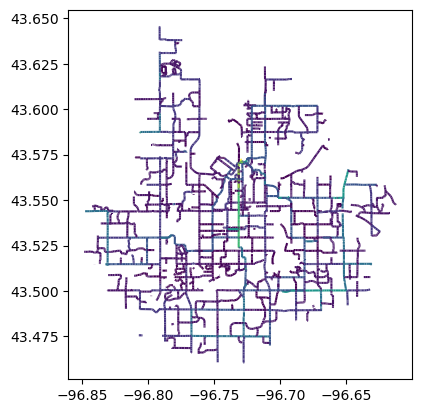

In [30]:
(tbl.as_geodataframe(field_names=["MAINID", "DIAMETER", "MATERIAL", "TRANSMISSION"],
                    to_crs=4269,
                    where_clause="DIAMETER > 8"
                    )
                .plot("DIAMETER")
)

### Open a cursor

In [ ]:
DB_CONN_WRT = Path(os.environ["EGDB_CONN_WRT"])                  # A .sde connection file


wmain = CatalogPath(
    name = "wMain",
    db_conn = DB_CONN_WRT,
    dataset_name="WaterDistribution",
    db_prefix=DB_PREFIX
)

with arcpy.da.Editor(workspace=str(wmain.workspace()), multiuser_mode=wmain.is_versioned()):
    with arcpy.da.SearchCursor(in_table=str(wmain), field_names = ["OBJECTID"]) as cursor:
        oids = [str(row[0]) for row in cursor]

print(f"OIDS: {', '.join(oids)}")

OIDS: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 59, 60, 61, 62, 63, 64, 65, 66, 67, 69, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 2

### Access table metadata

In [15]:
print(f"{tbl.name} ({tbl.pretty_path})")
print(f"Row Count: {tbl.row_count():,}")
print(f"Fields:")

for fname, ftype in tbl.field_types().items():
    print(f"    {fname:>16}: {ftype}")

Parcels (vcitygisdb1_sde_gisviewer.sde/sde.gis.Parcels/sde.gis.Parcels)
Row Count: 66,886
Fields:
            OBJECTID: OID
                 TAG: String
            COUNTYID: String
             ADDRESS: String
            OWNNAME1: String
            OWNNAME2: String
          OWNADDRESS: String
             OWNCITY: String
            OWNSTATE: String
              OWNZIP: String
             OWNZIP2: String
                SQFT: Double
             ACREAGE: Double
           FRONTFOOT: Double
               LEGAL: String
            ADDITION: String
         ADDITIONNUM: String
            PARHOUSE: String
             PARHALF: String
               PARPR: String
           PARSTREET: String
             PARTYPE: String
               PARPD: String
             UNITNUM: String
             LANDUSE: Integer
            NUMUNITS: Integer
              COUNTY: String
      LegalStartDate: Date
            GlobalID: GlobalID
        created_user: String
        created_date: Date
    la

Examine the dataclass signature in `interop.py` for a full list of the available methods. Keep in mind that CatalogPath was specifically designed to represent a path, not the table itself. This means accessing properties requires a new  `arcpy.Describe()` call to the database each time, since this information is not cached/stored on the object itself.